# 6 — Trade-off dos métodos de estabilidade

## Resumo

Este experimento compara quatro geradores: AST original, AST com coeficientes nos lags, AR estacionário por construção e AST não linear certificada por contração. Há exatamente uma linha por método. As ASTs começam dentro de $[-1,1]^L$; o AR começa em sua distribuição estacionária exata. Original, coefficient-gated e AR usam inovação gaussiana com desvio 0,05. A contração usa inovação uniforme limitada com o mesmo desvio-padrão, necessária para a garantia determinística de invariância do domínio. Medimos explosão, cauda de baixa amplitude, resultados intermediários e throughput.

## 1. Desenho da comparação

Cada linha representa um gerador completo com suas políticas de inicialização e ruído. Original, coefficient-gated e contraction-certified compartilham o mesmo histórico $U(-1,1)$ por índice. A AST contractive parte exatamente da AST coefficient-gated pareada e acrescenta uma escala calculada pelo certificado. O AR usa o histórico gaussiano determinado por sua covariância estacionária. As famílias e leis de ruído não são equivalentes; a tabela compara implementações utilizáveis e registra essas diferenças explicitamente.

In [1]:
from __future__ import annotations

from dataclasses import asdict, replace
from pathlib import Path
import importlib.metadata
import json
import platform
import subprocess
import sys
import time

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'src' / 'tsfmxai').exists():
            return candidate
    raise RuntimeError('Repository root not found.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SOURCE_ROOT = PROJECT_ROOT / 'src'
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

from tsfmxai.evaluation import (
    StabilityDiagnosticConfig,
    diagnose_stability_prefixes,
    wilson_interval,
)
from tsfmxai.generators import (
    ContractionTreeConfig,
    RandomTreeConfig,
    StationaryARConfig,
    evaluate_bound_expression,
    required_history_length,
    sample_contractive_mechanisms,
    sample_random_mechanisms,
    sample_stationary_ar_mechanisms,
)

ROOT_SEED = 20261001
SAMPLE_COUNT = 5_000
HORIZONS = (96, 192, 384)
REFERENCE_HORIZON = 192
INNOVATION_STD = 0.05
EXPLOSION_LIMIT = 100.0
NEAR_ZERO_RADIUS = 3.0 * INNOVATION_STD
NEAR_ZERO_TAIL_STEPS = 24
AST_INITIAL_MINIMUM = -1.0
AST_INITIAL_MAXIMUM = 1.0

DIAGNOSTIC_CONFIG = StabilityDiagnosticConfig(
    horizons=HORIZONS,
    explosion_limit=EXPLOSION_LIMIT,
    near_zero_radius=NEAR_ZERO_RADIUS,
    near_zero_tail_steps=NEAR_ZERO_TAIL_STEPS,
)
BASE_CONFIG = RandomTreeConfig(
    minimum_operators=1, maximum_operators=6, num_series=1,
    minimum_lag=1, maximum_lag=12, parameter_probability=0.55,
    time_probability=0.0, lag_probability=0.45, add_probability=0.80,
    minimum_parameter_magnitude=0.05, maximum_parameter_magnitude=0.80,
    require_lag=True, require_time=False, coefficient_gate_lags=False,
)
GATED_CONFIG = replace(BASE_CONFIG, coefficient_gate_lags=True)
CONTRACTION_CONFIG = ContractionTreeConfig(
    tree_config=GATED_CONFIG, domain_radius=1.0,
    innovation_bound=np.sqrt(3.0) * INNOVATION_STD,
    lag_weight_growth=1.25, target_lipschitz=0.90,
    scale_safety_factor=0.95,
)
STATIONARY_CONFIG = StationaryARConfig(
    minimum_order=1, maximum_order=12,
    partial_autocorrelation_minimum=-0.80,
    partial_autocorrelation_maximum=0.80,
    mean_minimum=0.0, mean_maximum=0.0,
    innovation_std_minimum=INNOVATION_STD,
    innovation_std_maximum=INNOVATION_STD,
)

configuration = {
    'root_seed': ROOT_SEED, 'sample_count_per_method': SAMPLE_COUNT,
    'horizons': list(HORIZONS), 'reference_horizon': REFERENCE_HORIZON,
    'innovation_std': INNOVATION_STD, 'explosion_limit': EXPLOSION_LIMIT,
    'near_zero_radius': NEAR_ZERO_RADIUS,
    'near_zero_tail_steps': NEAR_ZERO_TAIL_STEPS,
    'initialization_policy': {
        'original': 'paired Uniform(-1, 1) history',
        'coefficient-gated': 'paired Uniform(-1, 1) history',
        'contraction-certified': 'paired Uniform(-1, 1) history inside D',
        'stationary-by-construction': 'exact stationary Gaussian history',
    },
    'innovation_policy': {
        'original': 'Normal(0, 0.05^2)',
        'coefficient-gated': 'Normal(0, 0.05^2)',
        'stationary-by-construction': 'Normal(0, 0.05^2)',
        'contraction-certified': 'Uniform(-sqrt(3)*0.05, sqrt(3)*0.05)',
    },
    'baseline_tree_config': asdict(BASE_CONFIG),
    'gated_tree_config': asdict(GATED_CONFIG),
    'contraction_config': {
        **asdict(CONTRACTION_CONFIG),
        'tree_config': asdict(GATED_CONFIG),
    },
    'stationary_ar_config': asdict(STATIONARY_CONFIG),
}
print(json.dumps(configuration, indent=2))

{
  "root_seed": 20261001,
  "sample_count_per_method": 5000,
  "horizons": [
    96,
    192,
    384
  ],
  "reference_horizon": 192,
  "innovation_std": 0.05,
  "explosion_limit": 100.0,
  "near_zero_radius": 0.15000000000000002,
  "near_zero_tail_steps": 24,
  "initialization_policy": {
    "original": "paired Uniform(-1, 1) history",
    "coefficient-gated": "paired Uniform(-1, 1) history",
    "contraction-certified": "paired Uniform(-1, 1) history inside D",
    "stationary-by-construction": "exact stationary Gaussian history"
  },
  "innovation_policy": {
    "original": "Normal(0, 0.05^2)",
    "coefficient-gated": "Normal(0, 0.05^2)",
    "stationary-by-construction": "Normal(0, 0.05^2)",
    "contraction-certified": "Uniform(-sqrt(3)*0.05, sqrt(3)*0.05)"
  },
  "baseline_tree_config": {
    "minimum_operators": 1,
    "maximum_operators": 6,
    "num_series": 1,
    "minimum_lag": 1,
    "maximum_lag": 12,
    "parameter_probability": 0.55,
    "time_probability": 0.0,
    "

**O que foi feito.** A célula fixou o mesmo número de mecanismos, ruído, horizontes e limiares usados no experimento coefficient-gated. Para o AR estacionário, a média e o desvio da inovação foram fixados em zero e `0.05`; somente a ordem e os coeficientes PACF variam.

## 2. Amostragem dos mecanismos

Original e coefficient-gated recebem a mesma semente por índice, preservando a topologia e os lags antes da adição dos gates. O método estacionário recebe sementes derivadas da mesma raiz, mas sorteia outra família: uma ordem entre 1 e 12 e coeficientes PACF admissíveis.

In [2]:
sampling_times = {}
mechanisms_by_method = {}
samplers = {
    'original': lambda: sample_random_mechanisms(
        BASE_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT
    ),
    'coefficient-gated': lambda: sample_random_mechanisms(
        GATED_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT
    ),
    'contraction-certified': lambda: sample_contractive_mechanisms(
        CONTRACTION_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT
    ),
    'stationary-by-construction': lambda: sample_stationary_ar_mechanisms(
        STATIONARY_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT
    ),
}
for method, sampler in samplers.items():
    started = time.perf_counter()
    mechanisms_by_method[method] = sampler()
    sampling_times[method] = time.perf_counter() - started

original = mechanisms_by_method['original']
gated = mechanisms_by_method['coefficient-gated']
contractive = mechanisms_by_method['contraction-certified']
stationary = mechanisms_by_method['stationary-by-construction']
assert all(left.seed == right.seed for left, right in zip(original, gated))
assert all(
    left.expression == right.base_expression and left.binding == right.base_binding
    for left, right in zip(gated, contractive)
)
assert all(mechanism.certificate.holds for mechanism in contractive)
assert all(mechanism.certificate.holds for mechanism in stationary)

examples = pd.DataFrame([
    {
        'sample_index': index,
        'original': original[index].formula,
        'coefficient-gated': gated[index].formula,
        'contraction-certified': contractive[index].formula,
        'contraction_Lipschitz_bound': (
            contractive[index].certificate.lipschitz_upper_bound
        ),
        'stationary-by-construction': stationary[index].formula,
        'stationarity_margin': stationary[index].certificate.margin,
    }
    for index in range(3)
])
display(examples)
display(pd.Series(sampling_times, name='sampling_seconds').to_frame())

,sample_index,original,coefficient-gated,contraction-certified,contraction_Lipschitz_bound,stationary-by-construction,stationarity_margin
0,0,(((-0.727339 + 0.163988) + -0.752925) + x_0(t-7)),(((-0.727339 + 0.163988) + -0.752925) + (x_0(t...,x_0(t) = (0.611596 * (((-0.727339 + 0.163988) ...,0.800,x_0(t) = (((((((x_0(t-1) * 0.40497) + 0) + (x_...,0.013691
1,1,(((x_0(t-2) + -0.676288) + -0.610715) + x_0(t-...,((((x_0(t-2) * -0.198725) + -0.676288) + -0.61...,x_0(t) = (0.141423 * ((((x_0(t-2) * -0.198725)...,0.855,x_0(t) = ((((((x_0(t-1) * 0.261322) + 0) + (x_...,0.055927
2,2,(((x_0(t-10) + 0.0941167) + -0.285746) * (x_0(...,((((x_0(t-10) * 0.603961) + 0.0941167) + -0.28...,x_0(t) = (0.103955 * ((((x_0(t-10) * 0.603961)...,0.855,x_0(t) = (((((((((x_0(t-1) * 0.811428) + 0) + ...,0.037152


,sampling_seconds
original,1.655328
coefficient-gated,2.127074
contraction-certified,3.331790
stationary-by-construction,6.701171


**O que foi feito.** Foram sorteados 5.000 mecanismos de cada método e cronometrada apenas a construção dos objetos. A AST contraction-certified usa exatamente a estrutura e os bindings coefficient-gated do mesmo índice antes de aplicar sua escala. Todos os certificados AR e de contração foram verificados.

## 3. Simulação e diagnóstico

Para cada índice, as três ASTs recebem o mesmo histórico uniforme. O AR recebe um histórico compatível com sua normal multivariada estacionária. Original, coefficient-gated e AR compartilham inovações gaussianas; contraction-certified usa o mesmo subfluxo aleatório transformado em inovação uniforme limitada. Os horizontes reutilizam o mesmo prefixo. Uma explosão ocorre no primeiro valor não finito ou com módulo maior que 100. A `cauda de baixa amplitude` exige somente que os 24 últimos valores permaneçam em $[-0.15,0.15]$; ela não significa convergência para zero.

In [3]:
def simulate_prefix(mechanism, initial_values: np.ndarray, innovations: np.ndarray) -> np.ndarray:
    values = [float(value) for value in initial_values]
    generated = []
    history_length = len(values)
    for step, innovation in enumerate(innovations):
        next_value = evaluate_bound_expression(
            mechanism.expression, mechanism.binding,
            time=history_length + step, histories={0: values},
        ) + float(innovation)
        generated.append(float(next_value))
        if not np.isfinite(next_value) or abs(next_value) > EXPLOSION_LIMIT:
            break
        values.append(float(next_value))
    return np.asarray(generated, dtype=float)


def seeded_streams(
    sample_index: int,
) -> tuple[np.random.SeedSequence, np.random.SeedSequence]:
    sequence = np.random.SeedSequence([ROOT_SEED, sample_index, 991])
    initialization_sequence, innovation_sequence = sequence.spawn(2)
    return initialization_sequence, innovation_sequence


def native_innovations(method: str, mechanism, sequence) -> np.ndarray:
    rng = np.random.default_rng(sequence)
    if method == 'contraction-certified':
        bound = mechanism.certificate.innovation_bound
        return rng.uniform(-bound, bound, size=max(HORIZONS))
    return rng.normal(0.0, INNOVATION_STD, size=max(HORIZONS))


def native_initial_values(method: str, mechanism, sequence) -> np.ndarray:
    rng = np.random.default_rng(sequence)
    if method == 'stationary-by-construction':
        newest_to_oldest = rng.multivariate_normal(
            np.full(mechanism.order, mechanism.stationary_mean),
            np.asarray(mechanism.stationary_state_covariance),
            check_valid='raise',
        )
        return newest_to_oldest[::-1]
    history_length = required_history_length(
        mechanism.expression, mechanism.binding
    )
    return rng.uniform(
        AST_INITIAL_MINIMUM, AST_INITIAL_MAXIMUM, size=history_length
    )


outcome_rows = []
performance_rows = []
for method, mechanisms in mechanisms_by_method.items():
    if method == 'stationary-by-construction':
        initialization = 'exact stationary Gaussian history'
    elif method == 'contraction-certified':
        initialization = 'paired Uniform(-1, 1) history inside D'
    else:
        initialization = 'paired Uniform(-1, 1) history'
    noise = (
        'bounded Uniform with standard deviation 0.05'
        if method == 'contraction-certified'
        else 'Gaussian with standard deviation 0.05'
    )
    started = time.perf_counter()
    evaluated_steps = 0
    full_horizon_successes = 0
    for mechanism in mechanisms:
        initialization_sequence, innovation_sequence = seeded_streams(
            int(mechanism.sample_index)
        )
        initial_values = native_initial_values(
            method, mechanism, initialization_sequence
        )
        innovations = native_innovations(
            method, mechanism, innovation_sequence
        )
        generated = simulate_prefix(mechanism, initial_values, innovations)
        diagnostics = diagnose_stability_prefixes(generated, DIAGNOSTIC_CONFIG)
        evaluated_steps += len(generated)
        full_horizon_successes += len(generated) == max(HORIZONS)
        for diagnostic in diagnostics:
            outcome_rows.append({
                'method': method, 'initialization': initialization, 'noise': noise,
                'sample_index': int(mechanism.sample_index),
                'horizon': diagnostic.horizon,
                'exploded': diagnostic.exploded,
                'near_zero': diagnostic.near_zero,
                'neither': diagnostic.neither,
                'explosion_step': diagnostic.explosion_step,
            })
    elapsed = time.perf_counter() - started
    performance_rows.append({
        'method': method, 'initialization': initialization, 'noise': noise,
        'sampling_seconds': sampling_times[method],
        'sampled_mechanisms_per_second': SAMPLE_COUNT / sampling_times[method],
        'simulation_seconds': elapsed,
        'attempted_trajectories_per_second': SAMPLE_COUNT / elapsed,
        'evaluated_steps': evaluated_steps,
        'evaluated_steps_per_second': evaluated_steps / elapsed,
        'full_384_step_success_rate': full_horizon_successes / SAMPLE_COUNT,
    })

outcomes = pd.DataFrame(outcome_rows)
performance = pd.DataFrame(performance_rows)
assert len(outcomes) == len(mechanisms_by_method) * SAMPLE_COUNT * len(HORIZONS)
display(performance)

,method,initialization,noise,sampling_seconds,sampled_mechanisms_per_second,simulation_seconds,attempted_trajectories_per_second,evaluated_steps,evaluated_steps_per_second,full_384_step_success_rate
0,original,"paired Uniform(-1, 1) history",Gaussian with standard deviation 0.05,1.655328,3020.550314,5.061033,987.940565,1057495,208948.441595,0.4682
1,coefficient-gated,"paired Uniform(-1, 1) history",Gaussian with standard deviation 0.05,2.127074,2350.647277,11.405681,438.378021,1761125,154407.698557,0.8706
2,contraction-certified,"paired Uniform(-1, 1) history inside D",bounded Uniform with standard deviation 0.05,3.331790,1500.694957,14.219370,351.633019,1920000,135027.079259,1.0000
3,stationary-by-construction,exact stationary Gaussian history,Gaussian with standard deviation 0.05,6.701171,746.138272,24.254104,206.150680,1920000,79161.861260,1.0000


**O que foi feito.** Cada mecanismo gerou uma realização até 384 passos ou até a primeira explosão. As classificações foram calculadas pela API pública `tsfmxai.evaluation`, e o tempo inclui a execução da AST e a classificação, mas não a amostragem do mecanismo.

## 4. Resultados comparáveis

A tabela contém exatamente uma linha para cada método e registra explicitamente sua inicialização. Intervalos de Wilson de 95% acompanham as proporções de explosão e cauda de baixa amplitude.

In [4]:
summary = outcomes.groupby(['method', 'initialization', 'noise', 'horizon']).agg(
    evaluated_mechanisms=('sample_index', 'size'),
    explosions=('exploded', 'sum'), explosion_rate=('exploded', 'mean'),
    near_zero=('near_zero', 'sum'), near_zero_rate=('near_zero', 'mean'),
    neither=('neither', 'sum'), neither_rate=('neither', 'mean'),
    median_explosion_step=('explosion_step', 'median'),
).reset_index()
for metric in ('explosion', 'near_zero'):
    intervals = [
        wilson_interval(int(successes), int(trials))
        for successes, trials in zip(
            summary[f'{metric}s' if metric == 'explosion' else metric],
            summary['evaluated_mechanisms'],
        )
    ]
    summary[f'{metric}_wilson_95_low'] = [interval[0] for interval in intervals]
    summary[f'{metric}_wilson_95_high'] = [interval[1] for interval in intervals]

reference = summary[summary['horizon'].eq(REFERENCE_HORIZON)].copy()
main_reference = reference.copy()
display(main_reference)

stationary_margins = np.asarray([m.certificate.margin for m in stationary])
contraction_margins = np.asarray([
    m.certificate.contraction_margin for m in contractive
])
certificate_summary = pd.DataFrame([
    {
        'method': 'stationary-by-construction',
        'certified_mechanisms': int(sum(m.certificate.holds for m in stationary)),
        'margin': 'minimum root modulus minus one',
        'minimum_margin': stationary_margins.min(),
        'median_margin': np.median(stationary_margins),
        'maximum_margin': stationary_margins.max(),
    },
    {
        'method': 'contraction-certified',
        'certified_mechanisms': int(sum(m.certificate.holds for m in contractive)),
        'margin': 'one minus Lipschitz upper bound',
        'minimum_margin': contraction_margins.min(),
        'median_margin': np.median(contraction_margins),
        'maximum_margin': contraction_margins.max(),
    },
])
display(certificate_summary)


def outcome_cell(row: pd.Series, metric: str) -> str:
    count_column = 'explosions' if metric == 'explosion' else metric
    return (
        f"{int(row[count_column])} ({row[f'{metric}_rate']:.2%}; "
        f"CI95% {row[f'{metric}_wilson_95_low']:.2%}–"
        f"{row[f'{metric}_wilson_95_high']:.2%})"
    )


complete_rows = []
for performance_row in performance.itertuples(index=False):
    selected = summary[
        summary['method'].eq(performance_row.method)
    ].set_index('horizon')
    row = {
        'method': performance_row.method,
        'initialization': performance_row.initialization,
        'noise': performance_row.noise,
        'N': SAMPLE_COUNT,
    }
    for horizon in HORIZONS:
        outcome = selected.loc[horizon]
        row[f'h{horizon} explosion n (%; CI95%)'] = outcome_cell(outcome, 'explosion')
        row[f'h{horizon} low-amplitude n (%; CI95%)'] = outcome_cell(outcome, 'near_zero')
        row[f'h{horizon} neither n (%)'] = (
            f"{int(outcome['neither'])} ({outcome['neither_rate']:.2%})"
        )
    row.update({
        'median explosion step': selected.loc[REFERENCE_HORIZON, 'median_explosion_step'],
        'sampling seconds': performance_row.sampling_seconds,
        'mechanisms / second': performance_row.sampled_mechanisms_per_second,
        'simulation seconds': performance_row.simulation_seconds,
        'trajectories / second': performance_row.attempted_trajectories_per_second,
        'evaluated steps / second': performance_row.evaluated_steps_per_second,
        'full h384 success': performance_row.full_384_step_success_rate,
    })
    complete_rows.append(row)

complete_table = pd.DataFrame(complete_rows)
display(complete_table)

h384 = summary[summary['horizon'].eq(384)].copy()
publication_table = h384.merge(
    performance, on=['method', 'initialization', 'noise'], validate='one_to_one'
)
publication_table = publication_table[[
    'method', 'initialization', 'noise', 'explosion_rate', 'near_zero_rate',
    'neither_rate', 'full_384_step_success_rate', 'sampling_seconds',
    'sampled_mechanisms_per_second', 'simulation_seconds',
    'attempted_trajectories_per_second', 'evaluated_steps_per_second',
]].rename(columns={
    'method': 'method',
    'initialization': 'initialization',
    'noise': 'noise',
    'explosion_rate': 'h384 explosion',
    'near_zero_rate': 'h384 low-amplitude tail',
    'neither_rate': 'h384 neither',
    'full_384_step_success_rate': 'full h384 success',
    'sampling_seconds': 'sampling seconds',
    'sampled_mechanisms_per_second': 'mechanisms / second',
    'simulation_seconds': 'simulation seconds',
    'attempted_trajectories_per_second': 'trajectories / second',
    'evaluated_steps_per_second': 'evaluated steps / second',
})
display(publication_table)

,method,initialization,noise,horizon,evaluated_mechanisms,explosions,explosion_rate,near_zero,near_zero_rate,neither,neither_rate,median_explosion_step,explosion_wilson_95_low,explosion_wilson_95_high,near_zero_wilson_95_low,near_zero_wilson_95_high
1,coefficient-gated,"paired Uniform(-1, 1) history",Gaussian with standard deviation 0.05,192,5000,500,0.1000,917,0.1834,3583,0.7166,120.0,0.091989,0.108625,0.172918,0.194368
4,contraction-certified,"paired Uniform(-1, 1) history inside D",bounded Uniform with standard deviation 0.05,192,5000,0,0.0000,2207,0.4414,2793,0.5586,NaN,0.000000,0.000768,0.427687,0.455203
7,original,"paired Uniform(-1, 1) history",Gaussian with standard deviation 0.05,192,5000,2487,0.4974,522,0.1044,1991,0.3982,37.0,0.483548,0.511256,0.096226,0.113181
10,stationary-by-construction,exact stationary Gaussian history,Gaussian with standard deviation 0.05,192,5000,0,0.0000,1236,0.2472,3764,0.7528,NaN,0.000000,0.000768,0.235440,0.259348


,method,certified_mechanisms,margin,minimum_margin,median_margin,maximum_margin
0,stationary-by-construction,5000,minimum root modulus minus one,0.000006,0.019691,442.966403
1,contraction-certified,5000,one minus Lipschitz upper bound,0.145000,0.145000,0.995567


,method,initialization,noise,N,h96 explosion n (%; CI95%),h96 low-amplitude n (%; CI95%),h96 neither n (%),h192 explosion n (%; CI95%),h192 low-amplitude n (%; CI95%),h192 neither n (%),h384 explosion n (%; CI95%),h384 low-amplitude n (%; CI95%),h384 neither n (%),median explosion step,sampling seconds,mechanisms / second,simulation seconds,trajectories / second,evaluated steps / second,full h384 success
0,original,"paired Uniform(-1, 1) history",Gaussian with standard deviation 0.05,5000,2312 (46.24%; CI95% 44.86%–47.62%),528 (10.56%; CI95% 9.74%–11.44%),2160 (43.20%),2487 (49.74%; CI95% 48.35%–51.13%),522 (10.44%; CI95% 9.62%–11.32%),1991 (39.82%),2659 (53.18%; CI95% 51.79%–54.56%),520 (10.40%; CI95% 9.58%–11.28%),1821 (36.42%),37.0,1.655328,3020.550314,5.061033,987.940565,208948.441595,0.4682
1,coefficient-gated,"paired Uniform(-1, 1) history",Gaussian with standard deviation 0.05,5000,250 (5.00%; CI95% 4.43%–5.64%),918 (18.36%; CI95% 17.31%–19.46%),3832 (76.64%),500 (10.00%; CI95% 9.20%–10.86%),917 (18.34%; CI95% 17.29%–19.44%),3583 (71.66%),649 (12.98%; CI95% 12.08%–13.94%),944 (18.88%; CI95% 17.82%–19.99%),3407 (68.14%),120.0,2.127074,2350.647277,11.405681,438.378021,154407.698557,0.8706
2,contraction-certified,"paired Uniform(-1, 1) history inside D",bounded Uniform with standard deviation 0.05,5000,0 (0.00%; CI95% 0.00%–0.08%),2195 (43.90%; CI95% 42.53%–45.28%),2805 (56.10%),0 (0.00%; CI95% 0.00%–0.08%),2207 (44.14%; CI95% 42.77%–45.52%),2793 (55.86%),0 (0.00%; CI95% 0.00%–0.08%),2202 (44.04%; CI95% 42.67%–45.42%),2798 (55.96%),NaN,3.331790,1500.694957,14.219370,351.633019,135027.079259,1.0000
3,stationary-by-construction,exact stationary Gaussian history,Gaussian with standard deviation 0.05,5000,0 (0.00%; CI95% 0.00%–0.08%),1192 (23.84%; CI95% 22.68%–25.04%),3808 (76.16%),0 (0.00%; CI95% 0.00%–0.08%),1236 (24.72%; CI95% 23.54%–25.93%),3764 (75.28%),0 (0.00%; CI95% 0.00%–0.08%),1251 (25.02%; CI95% 23.84%–26.24%),3749 (74.98%),NaN,6.701171,746.138272,24.254104,206.150680,79161.861260,1.0000


**O que foi feito.** As contagens foram convertidas em proporções e intervalos de incerteza. A tabela do certificado responde a outra pergunta: todos os mecanismos AR satisfazem analiticamente a condição de estacionariedade antes de qualquer trajetória ser observada. A última tabela reúne os três métodos, suas inicializações, todos os horizontes e os indicadores de desempenho em uma única visão.

## 5. Trade-off visual e desempenho

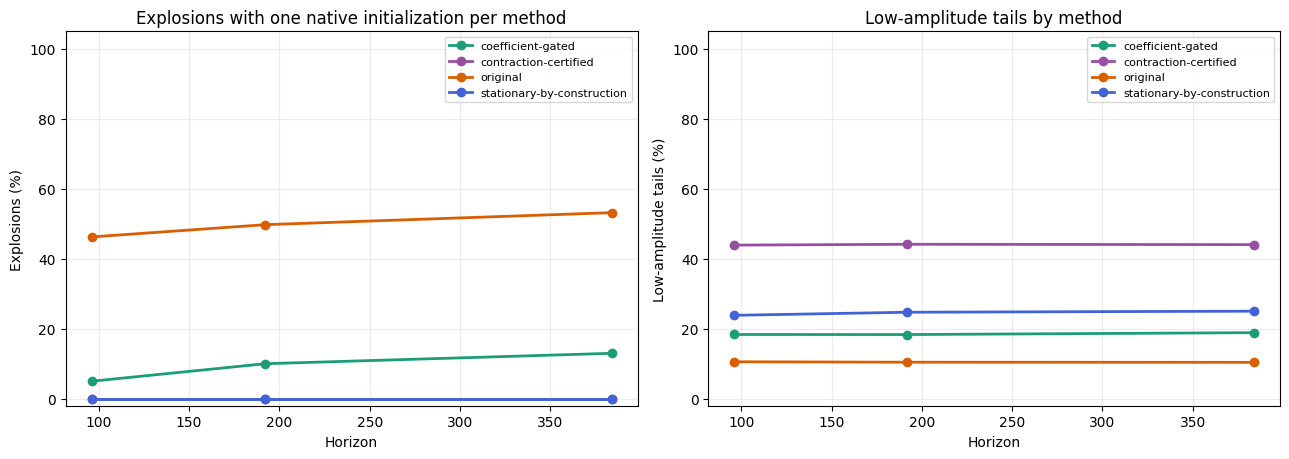

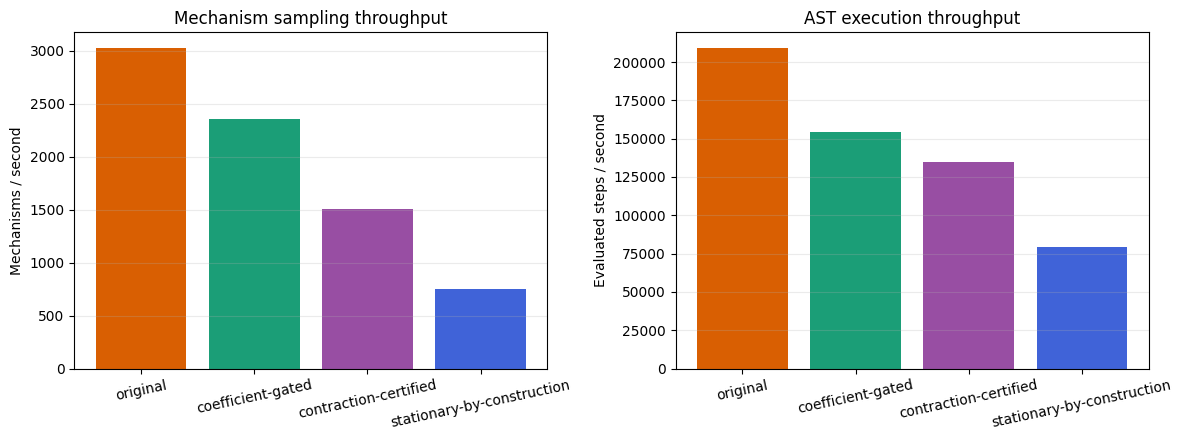

In [5]:
colors = {
    'original': '#d95f02',
    'coefficient-gated': '#1b9e77',
    'contraction-certified': '#984ea3',
    'stationary-by-construction': '#4063d8',
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
for method, group in summary.groupby('method'):
    group = group.sort_values('horizon')
    axes[0].plot(group['horizon'], 100 * group['explosion_rate'],
                 marker='o', linewidth=2, color=colors[method], label=method)
    axes[1].plot(group['horizon'], 100 * group['near_zero_rate'],
                 marker='o', linewidth=2, color=colors[method], label=method)
axes[0].set(title='Explosions with one native initialization per method',
            xlabel='Horizon', ylabel='Explosions (%)', ylim=(-2, 105))
axes[1].set(title='Low-amplitude tails by method',
            xlabel='Horizon', ylabel='Low-amplitude tails (%)', ylim=(-2, 105))
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()

method_performance = performance.set_index('method')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(method_performance.index,
            method_performance['sampled_mechanisms_per_second'],
            color=[colors[name] for name in method_performance.index])
axes[1].bar(method_performance.index,
            method_performance['evaluated_steps_per_second'],
            color=[colors[name] for name in method_performance.index])
axes[0].set(title='Mechanism sampling throughput', ylabel='Mechanisms / second')
axes[1].set(title='AST execution throughput', ylabel='Evaluated steps / second')
for axis in axes:
    axis.tick_params(axis='x', rotation=12)
    axis.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()

**O que foi feito.** Os primeiros painéis mostram como as classificações mudam com o horizonte. Os painéis de desempenho separam o custo de construir mecanismos do custo de executar seus nós AST; mecanismos que explodem cedo avaliam menos passos, razão pela qual `evaluated_steps_per_second` deve ser lido junto da taxa de sucesso até 384 passos. A amostragem estacionária inclui conversão PACF, certificado de raízes e solução da covariância de Lyapunov, enquanto a amostragem das outras duas linhas constrói somente a AST e seus bindings.

## 6. Interpretação

`coefficient-gated` é uma intervenção local na gramática original: reduz ganhos unitários implícitos, mas a soma dos ganhos e os produtos entre lags continuam sem restrição global. `stationary-by-construction` muda a família para uma recorrência AR linear cujas raízes são verificadas antes da simulação. `contraction-certified` preserva ASTs não lineares, mas aplica uma escala externa até certificar a norma ponderada da Jacobiana e a invariância de $[-1,1]^L$ sob ruído limitado. A garantia AR é global para o mecanismo linear e sua lei de inovação; a garantia por contração é restrita ao domínio e à lei uniforme declarados.

A métrica `near_zero` também não significa convergência assintótica. Com inovações em todos os passos, um processo estacionário preserva variância. O rótulo informa apenas que uma janela finita ficou dentro de três desvios-padrão da inovação.

## Registro completo do experimento

A célula seguinte é o registro autocontido do experimento executado.

In [6]:
def git_output(*arguments: str) -> str | None:
    try:
        return subprocess.check_output(
            ['git', *arguments], cwd=PROJECT_ROOT, text=True,
            stderr=subprocess.DEVNULL,
        ).strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None


def json_records(frame: pd.DataFrame) -> list[dict]:
    return json.loads(frame.to_json(orient='records'))


main_index = main_reference.set_index('method')
experiment_record = {
    'experiment_id': 'abstract_syntax_tree_006_stability_methods_tradeoff',
    'status': 'executed',
    'research_question': (
        'How do the original AST, coefficient-gated AST, stationary AR, and contraction-certified AST compare '
        'in finite-horizon explosion, low-amplitude tails, and generation throughput?'
    ),
    'configuration': configuration,
    'seed_policy': {
        'mechanism_seed': 'derive_sample_seed(ROOT_SEED, sample_index)',
        'initialization_seed': 'first child of SeedSequence([ROOT_SEED, sample_index, 991]).spawn(2)',
        'innovation_seed': 'second child of SeedSequence([ROOT_SEED, sample_index, 991]).spawn(2)',
        'same_uniform_history_for_all_ast_methods': True,
        'same_innovation_substream_per_sample_index': True,
        'same_innovation_distribution_across_methods': False,
        'external_global_rng_used': False,
    },
    'provenance': {
        'implementation': [
            'src/tsfmxai/generators/random_expression.py',
            'src/tsfmxai/generators/contraction.py',
            'src/tsfmxai/generators/stationary.py',
            'src/tsfmxai/generators/trajectory.py',
            'src/tsfmxai/evaluation/stability.py',
        ],
        'project_head': git_output('rev-parse', 'HEAD'),
        'python': sys.version, 'platform': platform.platform(),
        'packages': {name: importlib.metadata.version(name)
                     for name in ['numpy', 'pandas', 'matplotlib']},
    },
    'metrics': {
        'outcomes': json_records(summary),
        'generation_performance': json_records(performance),
        'complete_comparison_table': json_records(complete_table),
        'h384_stability_and_velocity_table': json_records(publication_table),
        'certificate_summary': json_records(certificate_summary),
    },
    'scientific_summary': (
        f"At horizon {REFERENCE_HORIZON} with one defined native initialization per method, explosion rates were "
        f"{main_index.loc['original', 'explosion_rate']:.2%} (original), "
        f"{main_index.loc['coefficient-gated', 'explosion_rate']:.2%} (coefficient-gated), "
        f"{main_index.loc['stationary-by-construction', 'explosion_rate']:.2%} (stationary by construction), and "
        f"{main_index.loc['contraction-certified', 'explosion_rate']:.2%} (contraction certified). "
        'Both construction-based methods are additionally supported by analytic certificates.'
    ),
    'limitations': [
        'The stationary implementation is linear AR, whereas the three AST families may contain lag products.',
        'Initialization and innovation law are part of each end-to-end method and are recorded in the table.',
        'The contraction guarantee is restricted to its declared domain and bounded uniform innovation law.',
        'Different innovation laws have matched standard deviation but prevent a fully distribution-paired comparison.',
        'A stationary Gaussian process is unbounded in support, so stationarity does not logically prohibit a finite threshold exceedance.',
        'Near-zero tails are a finite-window diagnostic and not proof of asymptotic convergence.',
        'Stationary and contraction sampling include certificate computations absent from the two uncertified AST samplers.',
        'Runtime was measured in one notebook execution and depends on hardware and early stopping.',
    ],
    'reproduction_command': (
        r'.\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace '
        r'experiments\abstract_syntax_tree\6_stability_methods_tradeoff.ipynb '
        r'--ExecutePreprocessor.timeout=2400'
    ),
}
print(json.dumps(experiment_record, indent=2, ensure_ascii=False))

{
  "experiment_id": "abstract_syntax_tree_006_stability_methods_tradeoff",
  "status": "executed",
  "research_question": "How do the original AST, coefficient-gated AST, stationary AR, and contraction-certified AST compare in finite-horizon explosion, low-amplitude tails, and generation throughput?",
  "configuration": {
    "root_seed": 20261001,
    "sample_count_per_method": 5000,
    "horizons": [
      96,
      192,
      384
    ],
    "reference_horizon": 192,
    "innovation_std": 0.05,
    "explosion_limit": 100.0,
    "near_zero_radius": 0.15000000000000002,
    "near_zero_tail_steps": 24,
    "initialization_policy": {
      "original": "paired Uniform(-1, 1) history",
      "coefficient-gated": "paired Uniform(-1, 1) history",
      "contraction-certified": "paired Uniform(-1, 1) history inside D",
      "stationary-by-construction": "exact stationary Gaussian history"
    },
    "innovation_policy": {
      "original": "Normal(0, 0.05^2)",
      "coefficient-gated": "No

**O que foi feito.** Esta célula única registra pergunta, configuração completa, política de sementes, proveniência, métricas, limitações, síntese científica e comando de reprodução. Nenhum sidecar é necessário.